In [58]:
import pandas as pd

df = pd.read_csv(
    "../data/raw/South Asian Wireless Telecom Operator (SATO 2015).csv"
)

print("Shape:", df.shape)
df.head()

Shape: (2000, 14)


,network_age,Aggregate_Total_Rev,Aggregate_SMS_Rev,Aggregate_Data_Rev,Aggregate_Data_Vol,Aggregate_Calls,Aggregate_ONNET_REV,Aggregate_OFFNET_REV,Aggregate_complaint_count,aug_user_type,sep_user_type,aug_fav_a,sep_fav_a,Class
0,1914,1592.7200,23.26,2.5,1.161130e+01,375,25523,99000,1,2G,2G,telenor,mobilink,Churned
1,2073,1404.1496,174.45,27.5,2.531725e+03,389,14584,77299,1,2G,2G,mobilink,ufone,Churned
2,3139,85.5504,14.34,5.0,2.913306e+04,15,477,4194,1,Other,Other,ptcl,telenor,Churned
3,139,2315.2292,19.25,52.5,2.674413e+05,636,50316,52400,2,2G,2G,telenor,ufone,Active
4,139,227.8620,2.95,42.5,1.461621e+06,17,2568,1701,1,NaN,NaN,mobilink,ufone,Active


In [59]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   network_age                2000 non-null   int64  
 1   Aggregate_Total_Rev        2000 non-null   float64
 2   Aggregate_SMS_Rev          2000 non-null   float64
 3   Aggregate_Data_Rev         2000 non-null   float64
 4   Aggregate_Data_Vol         2000 non-null   float64
 5   Aggregate_Calls            2000 non-null   int64  
 6   Aggregate_ONNET_REV        2000 non-null   int64  
 7   Aggregate_OFFNET_REV       2000 non-null   int64  
 8   Aggregate_complaint_count  2000 non-null   int64  
 9   aug_user_type              1755 non-null   str    
 10  sep_user_type              1794 non-null   str    
 11  aug_fav_a                  1999 non-null   str    
 12  sep_fav_a                  1999 non-null   str    
 13  Class                      2000 non-null   str    
dtypes: 

In [60]:
print(df.columns.tolist())

['network_age', 'Aggregate_Total_Rev', 'Aggregate_SMS_Rev', 'Aggregate_Data_Rev', 'Aggregate_Data_Vol', 'Aggregate_Calls', 'Aggregate_ONNET_REV', 'Aggregate_OFFNET_REV', 'Aggregate_complaint_count', 'aug_user_type', 'sep_user_type', 'aug_fav_a', 'sep_fav_a', 'Class']


### leakage check
#### Inspect the numerical relationships

In [61]:
df.corr(numeric_only=True)["Aggregate_Total_Rev"].sort_values(
    ascending=False
)

Aggregate_Total_Rev          1.000000
Aggregate_OFFNET_REV         0.716676
Aggregate_Data_Rev           0.616206
Aggregate_Calls              0.541560
Aggregate_ONNET_REV          0.430127
Aggregate_SMS_Rev            0.343828
network_age                  0.170512
Aggregate_Data_Vol           0.130510
Aggregate_complaint_count    0.088498
Name: Aggregate_Total_Rev, dtype: float64

In [62]:
revenue_cols = [
    "Aggregate_Total_Rev",
    "Aggregate_SMS_Rev",
    "Aggregate_Data_Rev",
    "Aggregate_ONNET_REV",
    "Aggregate_OFFNET_REV"
]

df[revenue_cols].corr()["Aggregate_Total_Rev"].sort_values(
    ascending=False
)

Aggregate_Total_Rev     1.000000
Aggregate_OFFNET_REV    0.716676
Aggregate_Data_Rev      0.616206
Aggregate_ONNET_REV     0.430127
Aggregate_SMS_Rev       0.343828
Name: Aggregate_Total_Rev, dtype: float64

High correlation alone isn't leakage, but if the total is calculated from those components, using them would make the prediction problem trivial.

#### Test whether Total Revenue is constructed from its components

In [63]:
df["Revenue_Sum"] = (
    df["Aggregate_SMS_Rev"]
    + df["Aggregate_Data_Rev"]
    + df["Aggregate_ONNET_REV"]
    + df["Aggregate_OFFNET_REV"]
)

df[[
    "Aggregate_Total_Rev",
    "Revenue_Sum"
]].head(10)

,Aggregate_Total_Rev,Revenue_Sum
0,1592.7200,124548.76
1,1404.1496,92084.95
2,85.5504,4690.34
3,2315.2292,102787.75
4,227.8620,4314.45
5,973.9664,19552.36
6,457.6752,23254.43
7,32.6800,351.45
8,1166.4000,3734.75
9,763.9200,28477.12


In [64]:
df["Revenue_Difference"] = (
    df["Aggregate_Total_Rev"] - df["Revenue_Sum"]
)

df["Revenue_Difference"].describe()

count      2000.000000
mean     -23053.756579
std       43518.868226
min     -802575.896800
25%      -25571.385100
50%       -8932.879600
75%       -2067.594000
max        4157.020000
Name: Revenue_Difference, dtype: float64

In [65]:
df[[
    "Aggregate_Total_Rev",
    "Revenue_Sum",
    "Revenue_Difference"
]].corr()

,Aggregate_Total_Rev,Revenue_Sum,Revenue_Difference
Aggregate_Total_Rev,1.000000,0.718507,-0.705587
Revenue_Sum,0.718507,1.000000,-0.999831
Revenue_Difference,-0.705587,-0.999831,1.000000


The revenue components are not simply summing to Aggregate_Total_Rev.\
Aggregate_Total_Rev    = 1,592.72\
Revenue_Sum            = 124,548.76

target: Aggregate_Total_Rev

we'll exclude:\
Aggregate_Total_Rev       ← target\
Aggregate_SMS_Rev         ← revenue component\
Aggregate_Data_Rev        ← revenue component\
Aggregate_ONNET_REV       ← revenue component\
Aggregate_OFFNET_REV      ← revenue component\
Revenue_Sum                ← derived revenue feature\
Revenue_Difference         ← derived using target\
Class                      ← churn outcome; not needed for revenue prediction

Initial features We'll use:\
network_age\
Aggregate_Data_Vol\
Aggregate_Calls\
Aggregate_complaint_count\
aug_user_type\
sep_user_type\
aug_fav_a\
sep_fav_a

### regression problem:
#### Can we predict a telecom customer's total revenue from their network tenure, usage volume, call activity, complaints, user type, and preferred operators?

#### final data-quality check

In [66]:
print(df["Aggregate_Total_Rev"].describe())

count     2000.000000
mean       905.020106
std       1151.308507
min          4.910000
25%        247.149600
50%        606.575000
75%       1220.045000
max      24438.830000
Name: Aggregate_Total_Rev, dtype: float64


In [67]:
df.isnull().sum().sort_values(ascending=False)

aug_user_type                245
sep_user_type                206
aug_fav_a                      1
sep_fav_a                      1
network_age                    0
Aggregate_Total_Rev            0
Aggregate_SMS_Rev              0
Aggregate_Data_Rev             0
Aggregate_Data_Vol             0
Aggregate_Calls                0
Aggregate_ONNET_REV            0
Aggregate_OFFNET_REV           0
Aggregate_complaint_count      0
Class                          0
Revenue_Sum                    0
Revenue_Difference             0
dtype: int64

In [68]:
df["Aggregate_Total_Rev"].skew()

np.float64(7.396281580305447)

We're checking:
1. Target range → understand what we're predicting.
2. Missing values → decide how to handle them.
3. Skewness → determine whether revenue has a heavily skewed distribution and whether we need to consider a transformation later.

Skewness: 7.40 (That is strongly right-skewed.)\
Only the categorical variables have missing values

### EDA

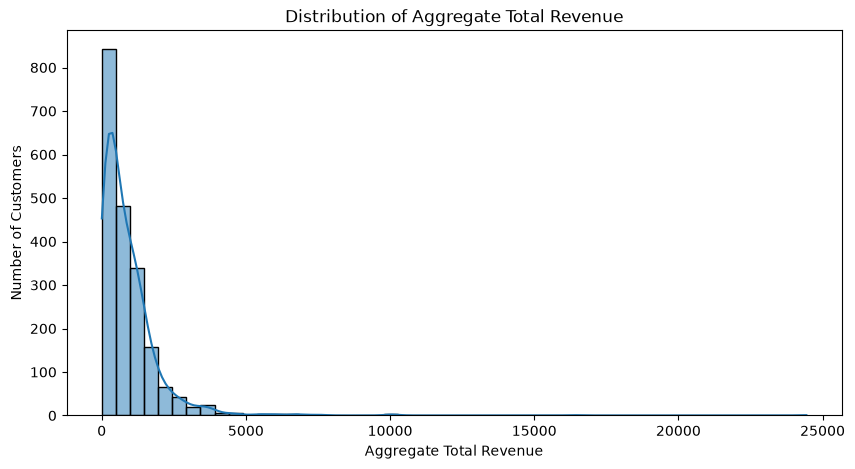

In [69]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(
    df["Aggregate_Total_Rev"],
    bins=50,
    kde=True
)

plt.title("Distribution of Aggregate Total Revenue")
plt.xlabel("Aggregate Total Revenue")
plt.ylabel("Number of Customers")
plt.show()

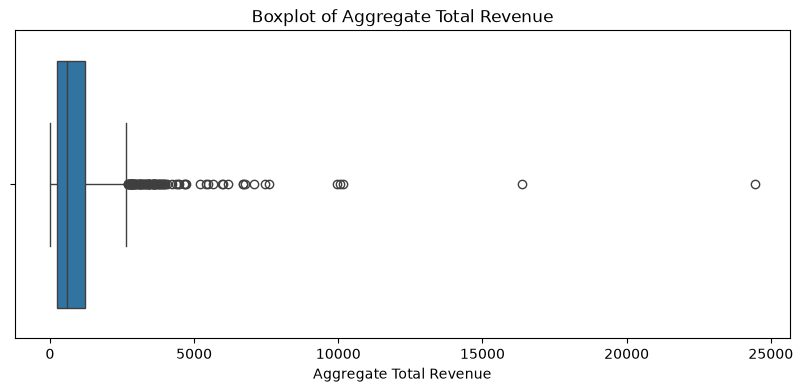

In [70]:
plt.figure(figsize=(10, 4))

sns.boxplot(
    x=df["Aggregate_Total_Rev"]
)

plt.title("Boxplot of Aggregate Total Revenue")
plt.xlabel("Aggregate Total Revenue")
plt.show()

These plots confirm the strong right skew we calculated.

From the histogram:
- Most customers have relatively low total revenue.
- A smaller number have much higher revenue.
- There is a long right tail extending beyond 20,000.

From the boxplot:
- There are many observations above the upper whisker.
- These are potential high-revenue outliers.
- We should not automatically remove them. In telecom, high-value customers can be legitimate and important.

#### Examine the numerical predictors

Now let's see how our numerical features relate to the target.

In [71]:
numeric_features = [
    "network_age",
    "Aggregate_Data_Vol",
    "Aggregate_Calls",
    "Aggregate_complaint_count"
]

df[numeric_features + ["Aggregate_Total_Rev"]].describe()

,network_age,Aggregate_Data_Vol,Aggregate_Calls,Aggregate_complaint_count,Aggregate_Total_Rev
count,2000.000000,2.000000e+03,2000.000000,2000.000000,2000.000000
mean,1469.554500,2.773961e+06,240.910500,1.924500,905.020106
std,1286.753291,8.845272e+06,369.922258,2.265693,1151.308507
min,-8.000000,5.860000e-02,1.000000,1.000000,4.910000
25%,323.500000,2.675567e+03,25.000000,1.000000,247.149600
50%,1194.500000,1.822864e+05,99.000000,1.000000,606.575000
75%,2247.250000,1.544505e+06,331.250000,2.000000,1220.045000
max,5451.000000,1.550312e+08,5727.000000,49.000000,24438.830000


create a correlation matrix

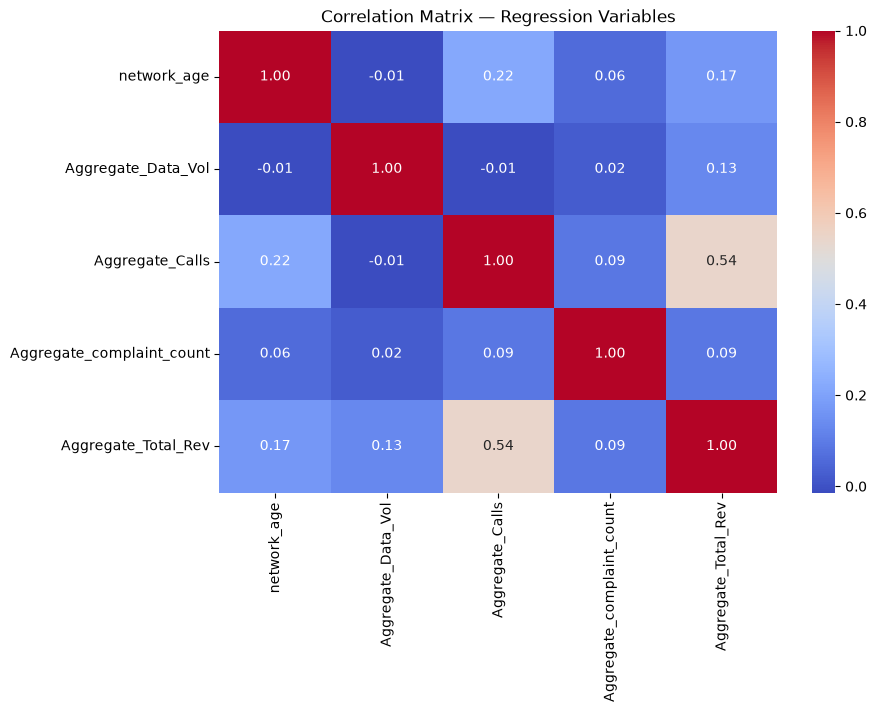

In [72]:
corr = df[numeric_features + ["Aggregate_Total_Rev"]].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix — Regression Variables")
plt.show()

The most important relationship at this stage is call activity with a moderate positive correlation of 0.54.\
The predictors also aren't strongly correlated with each other, That's useful because severe multicollinearity doesn't appear obvious from this simple correlation matrix.

Aggregate_Data_Vol has a huge range: Median:182,286, Maximum:  155,031,200\
while Aggregate_Calls ranges from: 1 → 5,727\
important for feature scaling and Ridge/Lasso.

A low Pearson correlation doesn't necessarily mean a feature is useless, especially for categorical variables or nonlinear relationships.

#### Examine categorical variables

In [73]:
categorical_features = [
    "aug_user_type",
    "sep_user_type",
    "aug_fav_a",
    "sep_fav_a"
]

for col in categorical_features:
    print(f"\n--- {col} ---")
    
    print(
        df.groupby(col)["Aggregate_Total_Rev"]
          .agg(["mean", "median", "count"])
          .round(2)
    )


--- aug_user_type ---
                  mean  median  count
aug_user_type                        
2G              664.69  466.73    407
3G             1131.76  876.34    974
Other           687.43  446.89    374

--- sep_user_type ---
                  mean  median  count
sep_user_type                        
2G              668.74  476.09    382
3G             1082.50  811.58   1038
Other           687.43  446.89    374

--- aug_fav_a ---
              mean   median  count
aug_fav_a                         
0          1504.55  1216.59     59
mobilink    902.61   682.79    289
ptcl        667.72   404.86    469
telenor    1069.16   764.64    286
ufone       780.24   508.41    446
warid      1076.21   860.53    209
zong       1112.36   867.11    241

--- sep_fav_a ---
              mean  median  count
sep_fav_a                        
mobilink    832.76  508.91    138
ptcl        353.69  242.12    423
telenor     697.67  438.37     82
ufone      1088.40  905.96   1212
warid      1671.4

Customers classified as 3G users have higher average aggregate revenue.

#### Investigate missing categorical values

In [74]:
missing_cols = [
    "aug_user_type",
    "sep_user_type",
    "aug_fav_a",
    "sep_fav_a"
]

for col in missing_cols:
    print(f"\n--- {col} ---")
    print("Missing:", df[col].isna().sum())
    print("Missing %:", round(df[col].isna().mean() * 100, 2))


--- aug_user_type ---
Missing: 245
Missing %: 12.25

--- sep_user_type ---
Missing: 206
Missing %: 10.3

--- aug_fav_a ---
Missing: 1
Missing %: 0.05

--- sep_fav_a ---
Missing: 1
Missing %: 0.05


In [75]:
for col in missing_cols:
    print(f"\n--- {col} ---")
    
    print(
        df.groupby(df[col].isna())["Aggregate_Total_Rev"]
          .agg(["mean", "median", "count"])
          .round(2)
    )


--- aug_user_type ---
                 mean  median  count
aug_user_type                       
False          928.75  642.05   1755
True           735.01  494.73    245

--- sep_user_type ---
                 mean  median  count
sep_user_type                       
False          912.03  611.26   1794
True           843.94  583.46    206

--- aug_fav_a ---
             mean  median  count
aug_fav_a                       
False      905.23  607.82   1999
True       481.90  481.90      1

--- sep_fav_a ---
             mean  median  count
sep_fav_a                       
False      905.23  607.82   1999
True       481.90  481.90      1


#### Final data-quality check

- network_age contains negative values (min = -8), A negative network age doesn't make obvious business sense, so we need to investigate it.\
- We should check whether the dataset contains duplicate records.

We're checking:\
Missing values       → handled\
Outliers             → investigate\
Invalid values       → investigate\
Duplicates           → investigate\
Categorical values   → inspect\
Target leakage       → already investigated

In [76]:
print("Negative network_age:")
print(df[df["network_age"] < 0][["network_age", "Aggregate_Total_Rev"]])

print("\nNumber of negative values:")
print((df["network_age"] < 0).sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Negative network_age:
     network_age  Aggregate_Total_Rev
594           -8             485.7008
595           -5             857.1008
596           -4            2898.8240
597           -3             307.1204
598           -2             130.5780

Number of negative values:
5

Duplicate rows:
0


inspect the categorical values

In [77]:
categorical_features = [
    "aug_user_type",
    "sep_user_type",
    "aug_fav_a",
    "sep_fav_a"
]

for col in categorical_features:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))


--- aug_user_type ---
aug_user_type
3G       974
2G       407
Other    374
NaN      245
Name: count, dtype: int64

--- sep_user_type ---
sep_user_type
3G       1038
2G        382
Other     374
NaN       206
Name: count, dtype: int64

--- aug_fav_a ---
aug_fav_a
ptcl        469
ufone       446
mobilink    289
telenor     286
zong        241
warid       209
0            59
NaN           1
Name: count, dtype: int64

--- sep_fav_a ---
sep_fav_a
ufone       1212
ptcl         423
mobilink     138
telenor       82
warid         74
zong          70
NaN            1
Name: count, dtype: int64


What we've confirmed:
1. No duplicate records.
2. network_age: 5 negative values, network_age cannot logically be negative, so these are invalid values. We should not simply delete them yet; we'll investigate whether they represent a special/missing value.
3. aug_user_type / sep_user_type: The missing values are genuine pandas NaN, and we preserved them as "Unknown".
4. sep_fav_a has no "0" category.
5. aug_fav_a contains "0" 59 times, Since aug_fav_a represents a favorite operator, "0" probably needs investigation rather than being treated as an ordinary operator.

Investigate these values:

A. Negative network_age

In [78]:
df.loc[
    df["network_age"] < 0
].T

,594,595,596,597,598
network_age,-8,-5,-4,-3,-2
Aggregate_Total_Rev,485.7008,857.1008,2898.824,307.1204,130.578
Aggregate_SMS_Rev,21.34,63.47,25.1,6.25,94.85
Aggregate_Data_Rev,0.0,190.03,1.25,75.0,1.25
Aggregate_Data_Vol,2327900.778,1565901.139,305853.3282,345076.2626,2.1953
Aggregate_Calls,607,204,642,9,7
Aggregate_ONNET_REV,0,716,0,477,150
Aggregate_OFFNET_REV,179,1240,82221,1284,1121
Aggregate_complaint_count,1,1,1,3,1
aug_user_type,Other,3G,3G,3G,Other


B. The "0" category in aug_fav_a

In [79]:
df.loc[
    df["aug_fav_a"] == "0"
].T

,8,17,62,84,127,149,151,236,259,324,...,1605,1630,1671,1766,1771,1793,1803,1871,1886,1988
network_age,443,1207,2501,3621,2169,1526,1994,958,1165,1649,...,743,1399,2087,1717,1882,2392,2890,1209,2109,5181
Aggregate_Total_Rev,1166.4,1753.16,2517.6648,1235.29,395.37,1015.8,488.916,3607.842,1357.13,129.6908,...,1216.594,423.07,711.7604,1359.412,1554.8,3170.14,1288.52,699.21,856.0384,1034.29
Aggregate_SMS_Rev,0.0,33.38,9.39,45.35,30.04,62.56,31.46,6.58,26.85,0.01,...,9.39,18.81,32.74,3.5,20.89,5.25,5.98,0.0,21.6,1.75
Aggregate_Data_Rev,28.75,126.25,411.25,0.0,13.75,61.25,46.25,211.25,0.0,27.5,...,75.0,3.75,6.25,243.75,12.5,41.25,115.0,0.62,237.15,1.25
Aggregate_Data_Vol,32954801.18,1064995.611,51514296.62,857.1758,22353.418,6402748.932,5483217.191,779097.3349,51771.2051,484796.5537,...,159984.2959,43262.2832,221.0459,1096163.608,284257.0214,8041.1484,880049.6084,2868393.475,3814302.774,1354.7891
Aggregate_Calls,209,361,270,561,37,175,28,1575,164,18,...,337,49,112,117,254,353,69,60,37,15
Aggregate_ONNET_REV,2400,10542,1428,900,5890,1548,252,17628,37349,526,...,10035,2892,5260,20988,20453,54514,622,13477,6169,741
Aggregate_OFFNET_REV,1306,63070,51080,6193,3033,7020,702,124294,1458,537,...,8528,5482,27573,30081,39265,73881,1995,5879,4007,5414
Aggregate_complaint_count,9,1,6,2,1,2,1,4,8,1,...,3,1,1,1,1,1,1,1,6,2
aug_user_type,3G,3G,3G,2G,3G,3G,3G,3G,3G,3G,...,3G,3G,3G,3G,3G,Other,3G,NaN,3G,2G


C. Check the data types of the categorical values

In [80]:
print(df["aug_fav_a"].dtype)
print(df["aug_fav_a"].dropna().unique())

str
<StringArray>
['telenor', 'mobilink', 'ptcl', 'ufone', '0', 'zong', 'warid']
Length: 7, dtype: str


the cleaning decisions with evidence:
1. Negative network_age:\
The five records have perfectly normal-looking telecom data around them, There is no meaningful interpretation for a negative network age, Because there are only 5 out of 2,000 rows (0.25%), we should treat these values as invalid/missing rather than delete the customers, We'll convert them to NaN and later impute them inside the preprocessing pipeline.
2. aug_fav_a == "0":\
We confirmed that "0" is stored as a string, 0 isn't one of the actual operator categories, so we'll treat it as an unknown/missing category, There are 59 customers, so we should preserve them rather than delete them.
3. no duplicate rows.

we should not manually fill network_age with its median right now. When we build the ML pipeline, we'll use SimpleImputer, so the median is calculated from the training data only. That's the proper way to avoid preprocessing leakage.

#### Create the clean modeling dataframe

In [81]:
import numpy as np

model_df = df.copy()

# Fix invalid network_age values
model_df.loc[
    model_df["network_age"] < 0,
    "network_age"
] = np.nan

# Treat "0" as an unknown category
model_df["aug_fav_a"] = model_df["aug_fav_a"].replace("0", np.nan)

# Keep only variables relevant to our regression problem
model_features = [
    "network_age",
    "Aggregate_Data_Vol",
    "Aggregate_Calls",
    "Aggregate_complaint_count",
    "aug_user_type",
    "sep_user_type",
    "aug_fav_a",
    "sep_fav_a"
]

target = "Aggregate_Total_Rev"

model_df = model_df[model_features + [target]]

print("Shape:", model_df.shape)
model_df.head()

Shape: (2000, 9)


,network_age,Aggregate_Data_Vol,Aggregate_Calls,Aggregate_complaint_count,aug_user_type,sep_user_type,aug_fav_a,sep_fav_a,Aggregate_Total_Rev
0,1914.0,1.161130e+01,375,1,2G,2G,telenor,mobilink,1592.7200
1,2073.0,2.531725e+03,389,1,2G,2G,mobilink,ufone,1404.1496
2,3139.0,2.913306e+04,15,1,Other,Other,ptcl,telenor,85.5504
3,139.0,2.674413e+05,636,2,2G,2G,telenor,ufone,2315.2292
4,139.0,1.461621e+06,17,1,NaN,NaN,mobilink,ufone,227.8620


verify the cleaning:

In [82]:
print("Negative network_age:", (model_df["network_age"] < 0).sum())
print("\nMissing values:")
print(model_df.isnull().sum())

Negative network_age: 0

Missing values:
network_age                    5
Aggregate_Data_Vol             0
Aggregate_Calls                0
Aggregate_complaint_count      0
aug_user_type                245
sep_user_type                206
aug_fav_a                     60
sep_fav_a                      1
Aggregate_Total_Rev            0
dtype: int64


## Save Prepared Modeling Data

The cleaned dataset is saved as a separate processed file so that the regression modeling notebook can run independently from the exploratory analysis notebook.

In [83]:
import os

processed_dir = "../data/processed"
os.makedirs(processed_dir, exist_ok=True)

model_df.to_csv(
    os.path.join(processed_dir, "telecom_regression_model_data.csv"),
    index=False
)

print("Saved prepared modeling data.")
print("Shape:", model_df.shape)
print("Path:", os.path.join(processed_dir, "telecom_regression_model_data.csv"))

Saved prepared modeling data.
Shape: (2000, 9)
Path: ../data/processed/telecom_regression_model_data.csv
